# M3 – Đặc trưng và model: phân tích

Notebook này **chỉ đọc kết quả** do các script tạo ra, rồi vẽ biểu đồ và giải thích. Nó không train lại gì. Các bước tính toán nằm trong script (chạy được trong `pipeline_m3.py` và trên Colab):

| Bước | Script | File ra (trong `WORK`) |
|---|---|---|
| đặc trưng | `src/m3/features.py` | `features.parquet`, `features.json` |
| phân tích từng đặc trưng (trên train) | `src/m3/feature_report.py --part train` | `feature_report_train.csv` |
| chọn model (cross-validation trên train) | `src/m3/modeling/train.py --feature-set full / compact` | `train_report_full.json`, `train_report.json`, `models/` |
| ablation + permutation importance (CV) | `src/m3/modeling/ablation.py` | `ablation_cv.csv`, `importance_cv.csv` |
| đánh giá | `src/m3/modeling/evaluate.py --part valid` (test: chạy **một lần** ở cuối) | `evaluation_valid.json` |
| bảng predictions | `src/m3/modeling/predict.py` | `predictions.parquet` |

**Quy ước:**
- Một **sample** là một entry có reference khớp (`is_sample = 1`), đúng định nghĩa nhãn của thầy.
- **MRR@5** chỉ tính trên các entry này.
- **"no link"**: che các đặc trưng arXiv ID/DOI, giả lập entry không ghi mã định danh.
- **"hard"**: entry mà reference đúng **không** có title giống hệt.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

WORK = Path("../../../data/m3_all")   # sửa nếu thư mục làm việc ở chỗ khác (ví dụ trên Colab)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
assert (WORK / "features.parquet").exists(), WORK.resolve()

## 1. Cách đặt bài toán

**Learning to rank.** Mỗi entry là một nhóm; ứng viên của nó là các reference có arXiv ID của **chính bài đó** (ma trận m×n của đề). Model chấm điểm từng cặp (entry, ứng viên), sắp xếp, rồi lấy top 5. Cách này khớp trực tiếp với MRR@5.

Để so sánh còn có:
- **phân loại cặp** (Logistic Regression);
- hai baseline: **rules** (luật gán nhãn tự động viết dưới dạng điểm) và **title** (chỉ độ giống title).

In [2]:
meta = json.loads((WORK / "features.json").read_text(encoding="utf-8"))
print(f"{meta['rows']:,} cặp, {meta['entries']:,} entry, {meta['samples']:,} sample")
pd.DataFrame([(g, f) for g, fs in meta["groups"].items() for f in fs], columns=["nhóm", "đặc trưng"]).groupby("nhóm")["đặc trưng"].apply(", ".join).to_frame()

4,636,680 cặp, 126,065 entry, 63,612 sample


,đặc trưng
nhóm,
author,"first_author_match, author_jacc, author_overla..."
context,"n_candidates, title_rank, title_gap_best, titl..."
link,"id_match, doi_match, entry_has_id, entry_has_d..."
title,"title_jacc3, title_jacc_word, title_tfidf, tit..."
venue,"venue_sim, entry_is_preprint, entry_type_code"
year,"year_gap, year_gap_signed, year_missing"


## 2. Từng đặc trưng trên tập train

Mỗi đặc trưng được đo bằng: trung bình ở cặp **đúng (yes)** và cặp **sai (no)**, và **MRR@5 khi chỉ dùng riêng nó để xếp hạng**. Đặc trưng cấp entry (cờ thiếu, `entry_has_id`, loại entry, số ứng viên) giống nhau cho mọi ứng viên của cùng entry, nên tự chúng không xếp hạng được (MRR ≈ 0). Chúng chỉ có ích khi kết hợp với đặc trưng khác.

In [3]:
rep = pd.read_csv(WORK / "feature_report_train.csv")
rep.sort_values("mrr5_alone", ascending=False)[["feature", "group", "missing", "mean_yes", "mean_no", "mrr5_alone", "mrr5_manual", "mrr5_auto"]]

,feature,group,missing,mean_yes,mean_no,mrr5_alone,mrr5_manual,mrr5_auto
6,title_jacc3,title,0.003,0.991,0.078,0.993,0.997,0.993
7,title_jacc_word,title,0.003,0.986,0.051,0.993,0.998,0.993
27,title_is_best,context,0.003,0.996,0.000,0.993,0.997,0.993
26,title_gap_best,context,0.003,0.000,0.911,0.993,0.997,0.993
25,title_rank,context,0.000,1.073,41.316,0.993,0.997,0.993
28,title_margin_second,context,0.000,0.729,0.000,0.993,0.997,0.993
8,title_tfidf,title,0.003,0.988,0.068,0.992,0.998,0.992
29,tfidf_rank,context,0.000,1.032,25.357,0.992,0.998,0.992
10,title_contain,title,0.003,0.967,0.001,0.954,0.952,0.954
9,title_exact,title,0.003,0.953,0.000,0.950,0.954,0.950


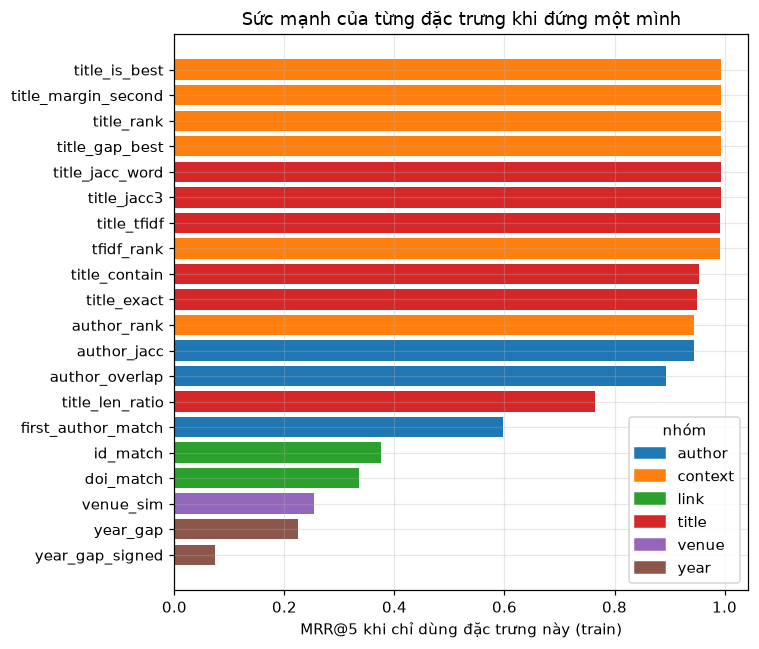

In [4]:
from matplotlib.patches import Patch
ranked = rep[rep.mrr5_alone > 0.01].sort_values("mrr5_alone")
colors = {g: c for g, c in zip(sorted(rep.group.unique()), plt.cm.tab10.colors)}
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(ranked.feature, ranked.mrr5_alone, color=[colors[g] for g in ranked.group])
ax.set_xlabel("MRR@5 khi chỉ dùng đặc trưng này (train)")
ax.set_title("Sức mạnh của từng đặc trưng khi đứng một mình")
ax.legend(handles=[Patch(color=colors[g], label=g) for g in sorted(ranked.group.unique())], loc="lower right", title="nhóm")
plt.tight_layout(); plt.show()

### Phân bố ở cặp đúng và cặp sai

Lấy mẫu từ các sample của train (mọi cặp đúng, cùng một mẫu cặp sai). Title và tác giả tách hai nhóm rất rõ. Chênh năm của cặp đúng tập trung ở 0–1 năm (bản preprint và bản đăng).

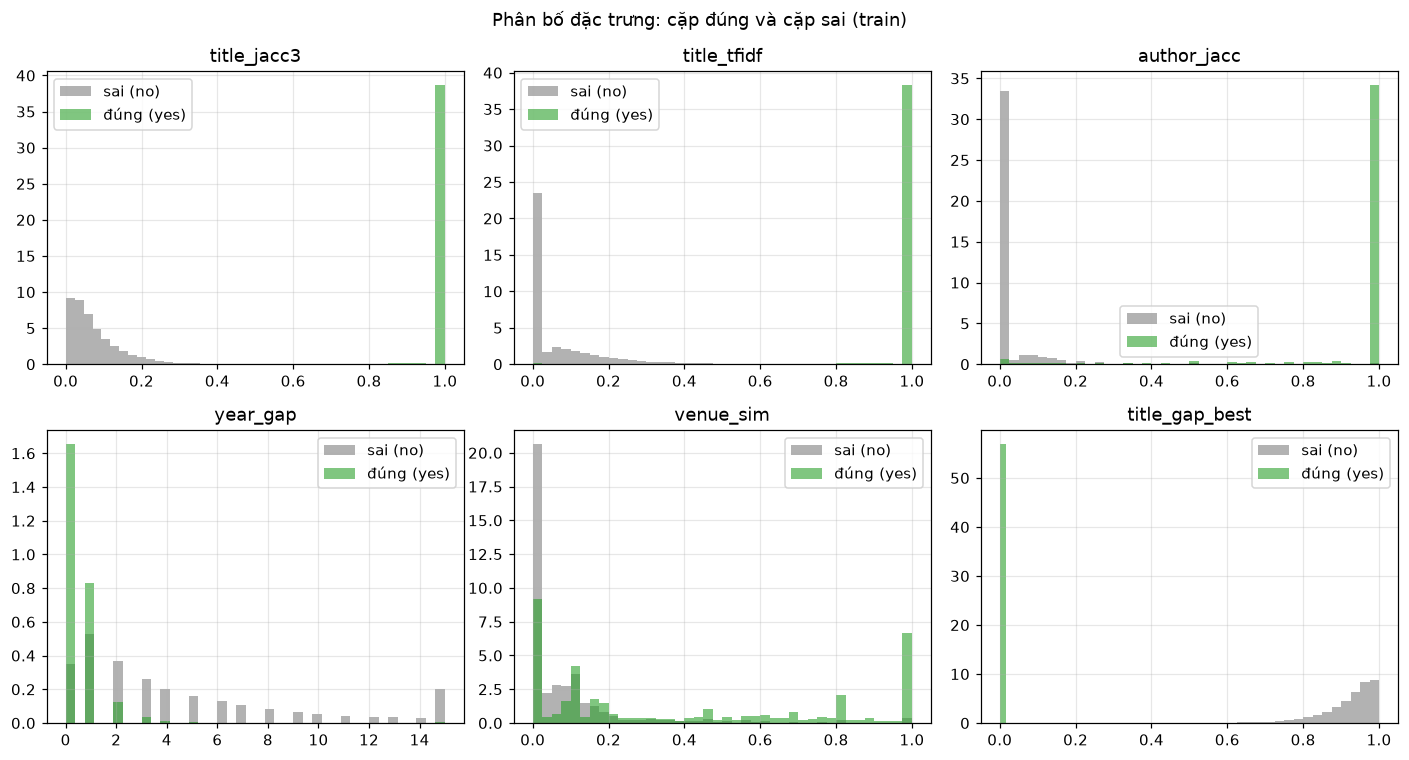

In [5]:
splits = json.loads((WORK / "splits.json").read_text(encoding="utf-8"))
cols = ["arxiv_id", "y", "is_sample", "title_jacc3", "title_tfidf", "author_jacc", "year_gap", "venue_sim", "title_gap_best"]
df = pq.read_table(WORK / "features.parquet", columns=cols, filters=[("is_sample", "=", 1)]).to_pandas()
df = df[df.arxiv_id.isin(set(splits["train"]))]
sample = pd.concat([df[df.y == 1], df[df.y == 0].sample(200_000, random_state=0)])
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, f in zip(axes.flat, ["title_jacc3", "title_tfidf", "author_jacc", "year_gap", "venue_sim", "title_gap_best"]):
    for y, lab, c in ((0, "sai (no)", "tab:gray"), (1, "đúng (yes)", "tab:green")):
        v = sample.loc[sample.y == y, f].dropna()
        if f == "year_gap":
            v = v.clip(upper=15)
        ax.hist(v, bins=40, density=True, alpha=0.6, label=lab, color=c)
    ax.set_title(f); ax.legend()
plt.suptitle("Phân bố đặc trưng: cặp đúng và cặp sai (train)"); plt.tight_layout(); plt.show()

### Tương quan giữa các đặc trưng

Các nhóm đặc trưng trùng lặp mạnh (|r| > 0,9):
- ba độ giống title (3-gram, từ, TF-IDF);
- `title_exact`, `title_contain` và các đặc trưng "là ứng viên tốt nhất";
- `entry_has_id`, `entry_id_in_paper` và `entry_is_preprint`.

Đây là lý do đầu tiên để rút gọn.

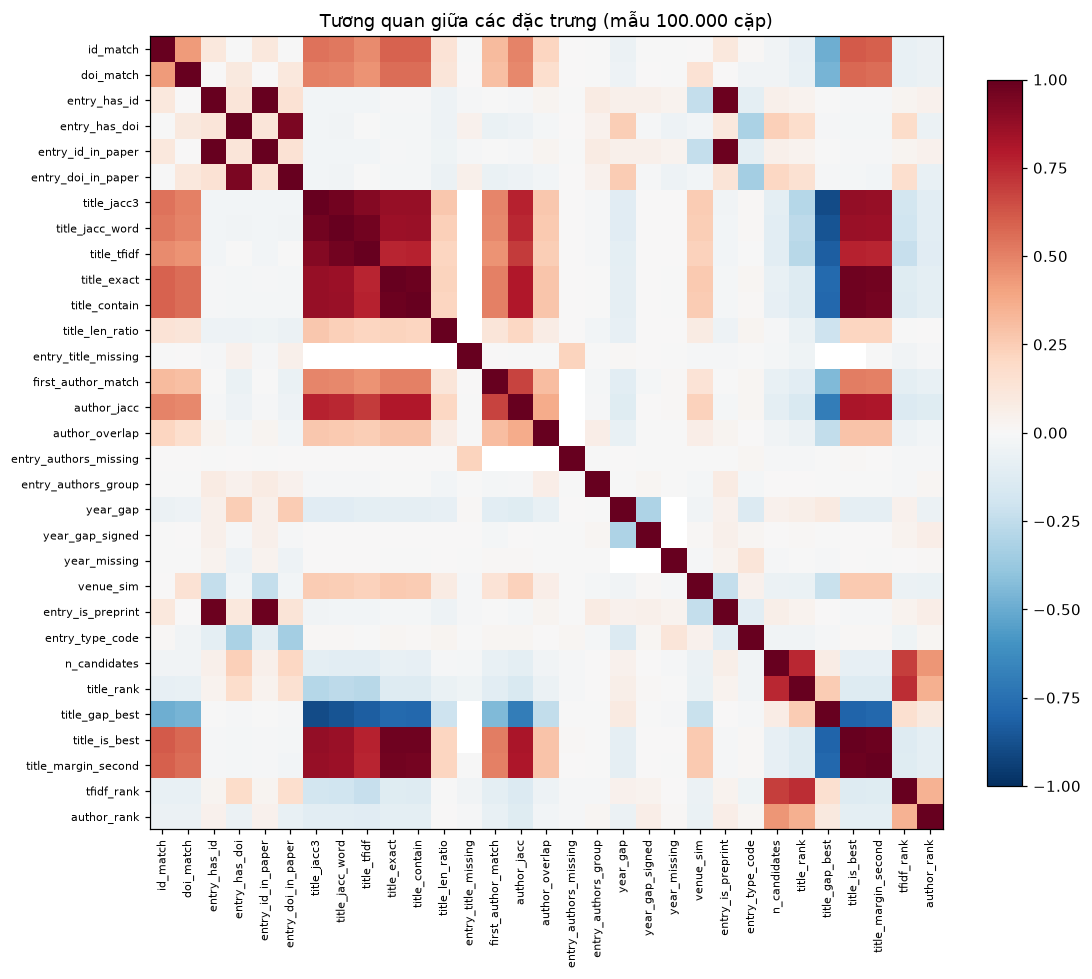

In [6]:
feats = [f for fs in meta["groups"].values() for f in fs]
corr_df = pq.read_table(WORK / "features.parquet", columns=feats, filters=[("is_sample", "=", 1)]).to_pandas().sample(100_000, random_state=0).corr()
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr_df.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(feats)), feats, rotation=90, fontsize=7); ax.set_yticks(range(len(feats)), feats, fontsize=7)
plt.colorbar(im, fraction=0.04); ax.set_title("Tương quan giữa các đặc trưng (mẫu 100.000 cặp)"); ax.grid(False)
plt.tight_layout(); plt.show()

## 3. So sánh model: cross-validation 5 fold theo bài trên train

Tập **valid quá dễ**: mọi model, kể cả baseline "chỉ title", đều đạt MRR@5 = 1. Vì vậy model được so sánh bằng **cross-validation 5 fold trên train**. Train được chia **theo bài**, nên một bài không bao giờ vừa nằm ở phần train vừa nằm ở phần chấm. Valid và test **không** dùng ở bước này.

Cách đọc:
- **"all" ≈ 1 với mọi model là chuyện hiển nhiên.** Phần lớn nhãn train do chính luật tạo ra, nên đây là vòng tròn.
- Con số có ý nghĩa là **"no link"** (entry không ghi ID/DOI), nhất là trên **ca khó** (title không trùng hệt).

**Các "model" trong bảng:**

| Tên | Là gì |
|---|---|
| `rules` | baseline: luật gán nhãn tự động viết dưới dạng điểm, `4×trùng arXiv ID + 4×trùng DOI + 2×title giống hệt + độ giống title`. Không học gì. |
| `title` | baseline: chỉ độ giống title (`title_jacc3`). Không học gì. |
| `logreg_m00`, `logreg_m50` | Logistic Regression (phân loại từng cặp đúng/sai) |
| `lgbm_m00`, `lgbm_m50` | LightGBM `lambdarank` (xếp hạng theo nhóm entry) |

Đuôi `_m00` / `_m50` là tỉ lệ entry bị **che đặc trưng link** khi train (0% / 50%): `id_match`, `doi_match`, `entry_has_id`, `entry_has_doi` được gán 0, như thể entry không ghi ID/DOI. Mục đích là buộc model học từ title, tác giả, năm, thay vì chỉ dựa vào ID.

**Số đặc trưng: 31 → 26 → 17.**
- `features.py` tính ra 31.
- Model không dùng 5 cái trùng lặp hoặc vô ích (mục 2). Còn **26**, gọi là bộ "full", dùng trong bảng dưới.
- Ablation ở mục 4 rút tiếp còn **17**, gọi là bộ "compact", dùng cho model cuối.

`features.parquet` vẫn giữ đủ 31 cột; danh sách nằm ở `src/m3/modeling/pairs.py` (`DROPPED`, `COMPACT`).

In [7]:
def cv_table(path):
    r = json.loads(Path(path).read_text(encoding="utf-8"))
    rows = []
    for name, c in r["cv"].items():
        rows.append({"model": name, "all": c["all"]["mrr5"], "manual": c["manual"]["mrr5"], "auto": c["auto"]["mrr5"],
                     "no link": c["all_nolink"]["mrr5"], "hard (no link)": c["hard_nolink"]["mrr5"],
                     "hard entries": c["hard_nolink"]["entries"]})
    return pd.DataFrame(rows).set_index("model"), r

full_tab, full_rep = cv_table(WORK / "train_report_full.json")
compact_tab, compact_rep = cv_table(WORK / "train_report.json")
print(f"full: {len(full_rep['features'])} đặc trưng, chọn {full_rep['chosen']}  |  compact: {len(compact_rep['features'])} đặc trưng, chọn {compact_rep['chosen']}")
full_tab

full: 26 đặc trưng, chọn lgbm_m50  |  compact: 17 đặc trưng, chọn lgbm_m50


,all,manual,auto,no link,hard (no link),hard entries
model,,,,,,
rules,1.0000,1.0000,1.0000,0.9934,0.8670,3119
title,0.9934,0.9969,0.9934,0.9934,0.8670,3119
logreg_m00,1.0000,1.0000,1.0000,0.9986,0.9719,3119
lgbm_m00,1.0000,1.0000,1.0000,0.9990,0.9795,3119
logreg_m50,1.0000,1.0000,1.0000,0.9990,0.9800,3119
lgbm_m50,0.9999,1.0000,0.9999,0.9993,0.9851,3119


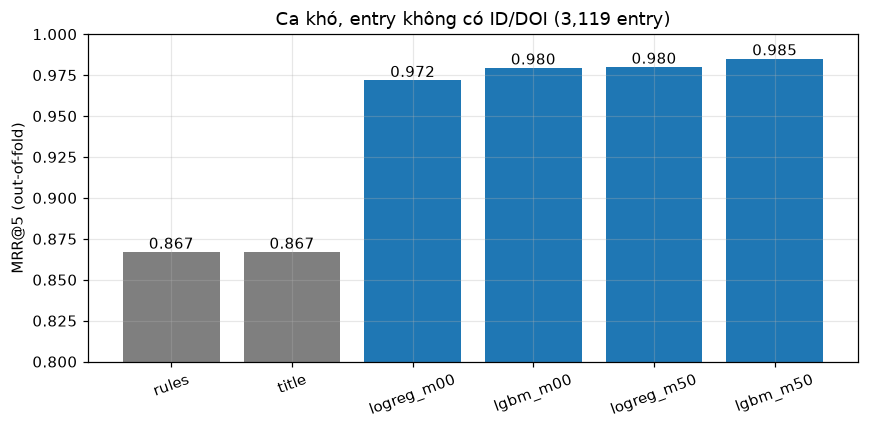

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
t = full_tab["hard (no link)"]
ax.bar(t.index, t.values, color=["tab:gray", "tab:gray"] + ["tab:blue"] * (len(t) - 2))
for i, v in enumerate(t.values):
    ax.text(i, v + 0.002, f"{v:.3f}", ha="center")
ax.set_ylim(0.8, 1.0); ax.set_ylabel("MRR@5 (out-of-fold)")
ax.set_title(f"Ca khó, entry không có ID/DOI ({int(full_tab['hard entries'].iloc[0]):,} entry)")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## 4. Ablation theo nhóm và permutation importance (CV trên train)

- **Ablation:** bỏ cả một nhóm đặc trưng, train lại (CV), xem MRR "ca khó, không link" giảm bao nhiêu.
- **Title và context** mang cùng một thông tin (độ giống title). Bỏ một trong hai thì nhóm kia bù lại, nên phải bỏ **cả hai** mới thấy vai trò của title.
- **Permutation importance:** xáo trộn từng đặc trưng trên phần chấm của mỗi fold (với link bị che), xem MRR giảm bao nhiêu. Đặc trưng trùng lặp thì importance riêng gần bằng 0, vì đặc trưng anh em đã bù lại.

,removed,features,mrr5,mrr5_nolink,mrr5_hard,drop,drop_nolink,drop_hard
0,(none),26,0.9999,0.9993,0.9851,0.0000,0.0000,0.0000
1,link,22,0.9993,0.9993,0.9850,0.0006,0.0000,0.0001
2,title,19,0.9999,0.9992,0.9848,0.0000,0.0001,0.0003
3,author,21,0.9997,0.9991,0.9809,0.0002,0.0002,0.0042
4,year,24,0.9999,0.9989,0.9778,0.0000,0.0004,0.0073
5,venue,24,1.0000,0.9992,0.9842,-0.0001,0.0001,0.0009
6,context,20,1.0000,0.9993,0.9861,-0.0001,0.0000,-0.0010
7,title+context,13,0.9951,0.9816,0.9548,0.0048,0.0177,0.0303


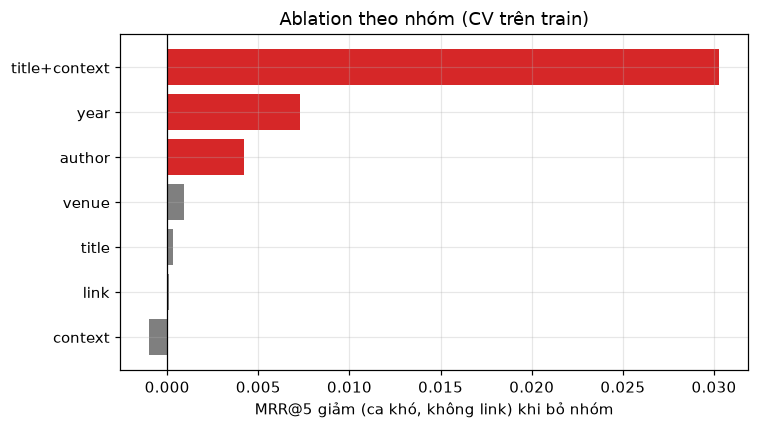

In [9]:
abl = pd.read_csv(WORK / "ablation_cv.csv")
display(abl)
a = abl[abl.removed != "(none)"].sort_values("drop_hard")
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(a.removed, a.drop_hard, color=["tab:red" if v > 0.002 else "tab:gray" for v in a.drop_hard])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("MRR@5 giảm (ca khó, không link) khi bỏ nhóm")
ax.set_title("Ablation theo nhóm (CV trên train)"); plt.tight_layout(); plt.show()

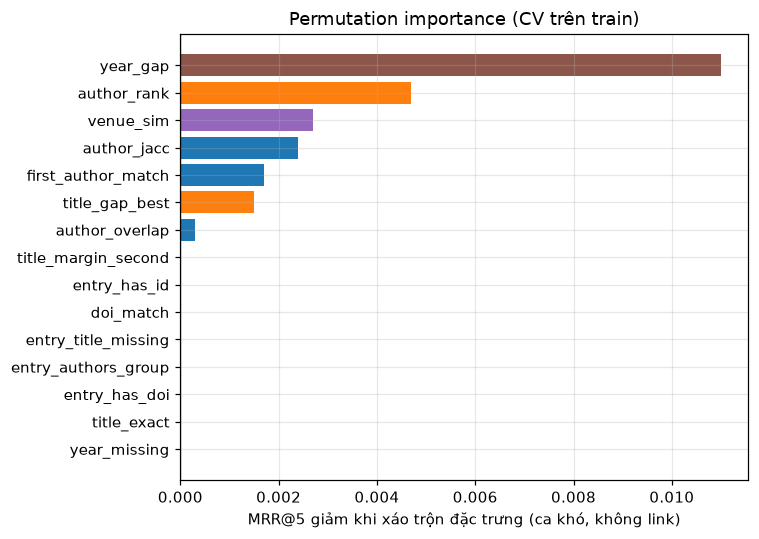

In [10]:
imp = pd.read_csv(WORK / "importance_cv.csv")
i = imp.sort_values("mrr5_drop_hard").tail(15)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(i.feature, i.mrr5_drop_hard, color=[colors.get(g, "gray") for g in i.group])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("MRR@5 giảm khi xáo trộn đặc trưng (ca khó, không link)")
ax.set_title("Permutation importance (CV trên train)"); plt.tight_layout(); plt.show()

## 5. Chọn đặc trưng

Từ phần 2–4:
1. **Bỏ 5 đặc trưng trùng lặp hoặc vô ích** ngay từ đầu: `entry_id_in_paper`, `entry_doi_in_paper` (≈ `entry_has_*`), `entry_is_preprint` (≈ `entry_has_id`), `year_gap_signed` (yes = no), `title_is_best` (≈ `title_rank = 1`). Còn lại 26 đặc trưng (**full**).
2. Rút gọn tiếp còn **compact (17)**:
   - **title:** giữ 3-gram + TF-IDF; bỏ word Jaccard, exact, contain, length ratio (trùng lặp, importance ≈ 0);
   - **context:** giữ `title_gap_best`, `author_rank` (importance > 0); bỏ các thứ hạng còn lại;
   - **venue:** chỉ giữ `venue_sim`;
   - **link, tác giả, năm:** giữ.
3. **Kiểm tra lại bằng CV:** compact phải **không kém** full ở mọi kịch bản. Bảng dưới đây là kết quả kiểm tra đó.

In [11]:
cmp = pd.DataFrame({"full (26)": full_tab.loc[full_rep["chosen"]], "compact (17)": compact_tab.loc[compact_rep["chosen"]]}).T
cmp[["all", "manual", "no link", "hard (no link)"]]

,all,manual,no link,hard (no link)
full (26),0.9999,1.0,0.9993,0.9851
compact (17),0.9999,1.0,0.9992,0.9849


In [12]:
print("Đặc trưng compact:", ", ".join(compact_rep["features"]))
ev = json.loads((WORK / "evaluation_valid.json").read_text(encoding="utf-8"))
pd.DataFrame({k: {"all": v["all"]["mrr5"], "manual": v.get("manual", {}).get("mrr5"), "auto": v.get("auto", {}).get("mrr5"),
                  "no link": v["all_nolink"]["mrr5"]} for k, v in ev["scorers"].items()}).T.rename_axis(f"valid ({ev['part']})")

Đặc trưng compact: id_match, doi_match, entry_has_id, entry_has_doi, title_jacc3, title_tfidf, entry_title_missing, first_author_match, author_jacc, author_overlap, entry_authors_missing, entry_authors_group, year_gap, year_missing, venue_sim, title_gap_best, author_rank


,all,manual,auto,no link
valid (valid),,,,
rules,1.0,1.0,1.0,1.0
title,1.0,1.0,1.0,1.0
lgbm_m00,1.0,1.0,1.0,1.0
lgbm_m50,1.0,1.0,1.0,1.0
logreg_m00,1.0,1.0,1.0,1.0
logreg_m50,1.0,1.0,1.0,1.0


## 6. Kết quả trên tập test (chấm **một lần**)

Đặc trưng và model đã được chốt trước, bằng CV trên train. Test chỉ được chấm **một lần**, bằng `evaluate.py --part test`. Test gồm 10 bài (mỗi thành viên 1 bài tay + 1 bài auto) với 346 entry có nhãn.

Trên test, các baseline **có xếp sai một vài entry**, nhất là ở bài gán tay. Model cuối xếp đúng toàn bộ.

In [13]:
evt = json.loads((WORK / "evaluation_test.json").read_text(encoding="utf-8"))
tab = pd.DataFrame({k: {"MRR@5 all": v["all"]["mrr5"], "manual": v["manual"]["mrr5"], "auto": v["auto"]["mrr5"],
                        "no link: all": v["all_nolink"]["mrr5"], "no link: manual": v["manual_nolink"]["mrr5"],
                        "Hit@1 manual": v["manual"]["hit1"]} for k, v in evt["scorers"].items()}).T
r0 = evt["scorers"]["rules"]
print(f"test: {r0['all']['entries']} entry có nhãn ({r0['manual']['entries']} tay, {r0['auto']['entries']} auto); model chọn: {evt['chosen']}")
tab

test: 346 entry có nhãn (138 tay, 208 auto); model chọn: lgbm_m50


,MRR@5 all,manual,auto,no link: all,no link: manual,Hit@1 manual
rules,0.9986,0.9964,1.0000,0.9908,0.9843,0.9928
title,0.9908,0.9843,0.9952,0.9908,0.9843,0.9783
lgbm_m00,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
lgbm_m50,1.0000,1.0000,1.0000,0.9986,0.9964,1.0000
logreg_m00,1.0000,1.0000,1.0000,0.9957,0.9928,1.0000
logreg_m50,1.0000,1.0000,1.0000,0.9971,0.9964,1.0000


## 7. Phân tích lỗi

`src/m3/modeling/errors.py` liệt kê mọi entry mà **model** hoặc **baseline title** không xếp đáp án ở vị trí 1, trên hai nguồn:
- **test**;
- **train (out-of-fold)**: nhiều entry hơn nhiều, có đủ ca khó.

Mỗi nguồn được xét ở hai kịch bản: bình thường và **không link**.
- **"model fixes"**: baseline title xếp sai, model xếp đúng.
- **"model breaks"**: ngược lại.

In [14]:
errs = json.loads((WORK / "errors_summary.json").read_text(encoding="utf-8"))
pd.DataFrame({k: {"entry": v["entries"], "model sai (rank > 1)": v["model_not_first"],
                  "baseline title sai": v["title_baseline_not_first"], "model fixes": v["model_fixes"],
                  "model breaks": v["model_breaks"], "loại lỗi của model": v["categories"]}
              for k, v in errs.items() if "entries" in v}).T

,entry,model sai (rank > 1),baseline title sai,model fixes,model breaks,loại lỗi của model
test / as is,346,0,4,4,0,{}
test / no link,346,1,4,3,0,{'rewritten title': 1}
train_cv / as is,62866,10,457,447,0,"{'missing information': 7, 'close candidates':..."
train_cv / no link,62866,71,457,390,4,"{'rewritten title': 35, 'missing information':..."


**Đọc kết quả:**
- Trên train (out-of-fold), baseline title xếp sai **457** entry. Model chỉ sai **10** (khi có link) và **71** (khi không link): sửa được khoảng **390–447** ca, trong khi chỉ làm hỏng tối đa 4 ca.
- Các lỗi còn lại của model gồm hai loại chính:
  - **"rewritten title"**: title của entry rất khác title của reference. Nguyên nhân có thể là bài đổi tên, S2 lưu title rác (`OUP accepted manuscript`, mã MathML), hoặc M2 lấy nhầm tên tác giả/tạp chí làm title (ví dụ title của entry là `"Folkestad"` hay `"arXiv:2411.17604"`).
  - **"missing information"**: entry không có title. Khi đó chỉ còn tác giả và năm để phân biệt các bài **cùng tác giả**.
- Các lỗi này phần lớn bắt nguồn từ **dữ liệu**: lỗi parse ở M2, title rác ở S2. Model khó sửa được, nhưng nếu cải thiện việc làm sạch title ở M2 và M3 thì có thể giảm.

In [15]:
ex = pd.read_csv(WORK / "errors.csv")
cols = ["source", "setting", "category", "model_rank", "title_baseline_rank", "entry_title", "entry_first_author",
        "gold_title", "first_title"]
print("Một số lỗi của model (không link, train out-of-fold):")
display(ex[(ex.source == "train_cv") & (ex.setting == "no link") & (ex.model_rank > 1)].sample(8, random_state=1)[cols])
print("Các ca baseline title sai nhưng model đúng (test):")
display(ex[(ex.source == "test") & (ex.setting == "as is") & (ex.model_rank == 1)][cols])

Một số lỗi của model (không link, train out-of-fold):


,source,setting,category,model_rank,title_baseline_rank,entry_title,entry_first_author,gold_title,first_title
836,train_cv,no link,rewritten title,2,14,"JHEP 03, 150","Ibe, M.",Comprehensive Bayesian exploration of Froggatt...,Nucleon decay as a probe of flavor symmetry: t...
637,train_cv,no link,rewritten title,2,2,First simultaneous measurement of ^0 and ^0 as...,Ablikim,First simultaneous measurement of <mml:math xm...,Precise Measurements of Decay Parameters and C...
864,train_cv,no link,missing information,3,1,arXiv preprint,NaN,GPT-4 Technical Report,The Benefit of Hindsight: Tracing Edge-Cases i...
767,train_cv,no link,missing information,2,65,NaN,"Metzger, B. D.",Gamma-ray novae as probes of relativistic part...,High-energy Emission from Nonrelativistic Radi...
638,train_cv,no link,rewritten title,10,11,Measurement of e^+ e^- p K^- + c.c. cross sect...,Ablikim,Measurement of e+e−→pK−Λ¯+c.c.\documentclass[1...,"Tests of <mml:math xmlns:mml=""http://www.w3.or..."
791,train_cv,no link,missing information,3,65,NaN,—,Internal shocks from variable outflows in clas...,Internal shocks from variable outflows in clas...
757,train_cv,no link,missing information,7,65,NaN,"Finzell, T.",A Detailed Observational Analysis of V1324 Sco...,New Insights into Classical Novae
700,train_cv,no link,missing information,3,51,NaN,NaN,Search for flavor-changing neutral current int...,Constraining the 3HDM Parameter Space using Ac...


Các ca baseline title sai nhưng model đúng (test):


,source,setting,category,model_rank,title_baseline_rank,entry_title,entry_first_author,gold_title,first_title
0,test,as is,(baseline only),1,101,<scp>compaso</scp>: A new halo finder for comp...,"Hadzhiyska, Boryana",OUP accepted manuscript,OUP accepted manuscript
1,test,as is,(baseline only),1,25,Folkestad,"Engelhardt, N.",Canonical purification of evaporating black holes,Canonical purification of evaporating black holes
2,test,as is,(baseline only),1,2,Evaluating Large Language Models in Class-Leve...,"Du, Xueying",ClassEval: A Manually-Crafted Benchmark for Ev...,ClassEval: A Manually-Crafted Benchmark for Ev...
3,test,as is,(baseline only),1,3,"CoverUp: Coverage-Guided, LLM-Based Test Gener...","Pizzorno, Juan Altmayer",CoverUp: Effective High Coverage Test Generati...,CoverUp: Effective High Coverage Test Generati...


## 8. Hạn chế: dữ liệu lệch về phía dễ

Vì sao MRR@5 gần 1? Có bốn nguyên nhân, đều nằm ở **dữ liệu**, không phải lỗi code:
1. **Nhãn auto là vòng tròn.** 2.500/2.525 bài có nhãn do luật tạo ra, mà model lại dùng chính các tín hiệu đó (ID, DOI, title giống hệt). Baseline `rules` cũng đạt khoảng 1.
2. **Bài gán tay được chọn thiên về bài dễ.** Để mỗi bài đạt ≥ 20 cặp khớp, chỉ chọn bài mà S2 liên kết tốt (n ≥ 25, luật đã tìm được ≥ 10 reference).
3. **Bài toán dễ trên dữ liệu này.** Mỗi entry chỉ so với khoảng 40 reference của chính bài, mà người ta thường trích gần đúng nguyên title.
4. **Entry không khớp không được chấm**, theo định nghĩa của đề. Vì vậy phần khó nhất (nhận ra entry không có trên arXiv) không có trong |Q|.

**Thiên lệch do luật bỏ sót.** Luật auto ưu tiên precision (0,999); recall đo trên nhãn tay độc lập là 0,987. Các cặp khớp mà luật bỏ sót **không trở thành sample**. Chúng thường là ca khó: title 2 từ, năm lệch 2, title lẫn tên tác giả hoặc năm, bài đổi tên. Bảng dưới đếm các entry "không khớp" mà ứng viên tốt nhất (theo model) trông như cùng một bài.
- Ở bài **tay** (người đã duyệt) gần như không có ca nào.
- Ở bài **auto** có khoảng **400–760** ca.

Mình **không sửa luật** để bắt các ca này, vì hai lý do. Nới luật sẽ kéo theo ca "giống mà khác" (`Qwen2.5` ↔ `Qwen3`, `Langlands I` ↔ `IV`). Và nhãn tay hầu như không có loại ca này, nên không đo được precision sau khi nới. Phát hiện này được ghi lại như một hạn chế.

In [16]:
miss = errs["possibly missed matches"]
display(pd.DataFrame({k: v for k, v in miss.items()}).T.fillna(0).astype(int))
mm = pd.read_csv(WORK / "missed_matches.csv")
mm[mm.source == "auto"].sample(10, random_state=4)[["entry_title", "entry_year", "candidate_title", "candidate_year", "title_sim"]]

,auto,manual
entries without label,61855,598
title >= 0.8 + first author,427,2
title >= 0.6 + authors >= 0.3,678,2
title >= 0.5 + first author + years <= 2,764,4


,entry_title,entry_year,candidate_title,candidate_year,title_sim
577,A mass formula for linear codes with prescribe...,2025,A further study on the mass formula for linear...,2024,0.500
215,Superconductivity in sr-doped la3ni2o7 thin fi...,2025,Superconductivity and phase diagram in Sr-dope...,2025,0.578
421,Analysis of the extended coupled-cluster metho...,2018,Analysis of the Tailored Coupled-Cluster Metho...,2018,0.750
584,Inception transformer,2022,Inception Transformer,2022,1.000
746,World models,2018,World Models,2018,1.000
77,On the prony series representation of the stre...,2018,On the Prony series representation of stretche...,2018,0.836
466,Quantum natural gradient optimizer on noisy pl...,2025,Quantum Natural Gradient optimizer on noisy pl...,2025,0.622
279,Investigating the conformal behaviour of SU(2)...,2021,Investigating the conformal behavior of SU(2) ...,2021,0.787
730,Random walks on simplicial complexes and the n...,2020,Random Walks on Simplicial Complexes and the n...,2018,0.917
195,On the bound states of Schrödinger operators w...,2016,Schrödinger operators with δ-interactions supp...,2014,0.535


## 9. Kết luận

- **Tín hiệu mạnh nhất là title.** Tác giả và năm **phân xử** các bài trùng tên hoặc gần trùng tên. Link (arXiv ID/DOI) gần như không bao giờ sai, nhưng chỉ có ở khoảng 1/3 số entry.
- **Model:** LightGBM `lambdarank`, 17 đặc trưng (compact), **che link ở 50% entry khi train**. Chọn bằng CV 5 fold theo bài trên train, vì valid quá dễ để phân biệt các model.
- **Test (chấm một lần):** MRR@5 = **1,000** (tay 1,000, auto 1,000); khi không link là 0,9986. Baseline: luật 0,9986 (tay 0,9964), title 0,9908 (tay 0,9843).
- **Năng lực thật:** đo trên **ca khó khi không có link** (CV trên train). Baseline đạt 0,867, LightGBM đạt 0,985; số entry xếp sai giảm từ 457 xuống 71.
- **Hạn chế:** nhãn auto là vòng tròn, bài tay thiên về dễ, luật bỏ sót khoảng 1,3% cặp khớp (phần lớn là ca khó), và entry không khớp không được chấm. Lỗi còn lại của model chủ yếu do dữ liệu: title bị M2 parse sai, hoặc S2 lưu title rác.